# Comparação e Otimização de Modelos de Regressão: previsão da concentração de CO no ar

- Variável-alvo: CO(GT) (numérica contínua, concentração de monóxido de carbono em mg/m³)
- Features: leituras de sensores de qualidade do ar (óxidos de nitrogênio, ozônio, benzeno) e variáveis ambientais (temperatura, umidade relativa e absoluta)
- Objetivo: dado um conjunto de leituras dos sensores, o modelo deve estimar corretamente a concentração de CO
- Algoritmos: MLPRegressor (rede neural, família apresentada no seminário) e GradientBoostingRegressor (ensemble de boosting, diferente do ExtraTreesRegressor visto em aula)


In [1]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import loguniform, randint, uniform

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## Explorando os dados


In [2]:
url = "https://raw.githubusercontent.com/klaytoncastro/idp-machinelearning/main/datasets/AirQualityUCI.csv"
df = pd.read_csv(url, delimiter=';', decimal=',')

# O arquivo original possui dois separadores ';' extras ao final de cada linha,
# gerando duas colunas totalmente vazias ('Unnamed: 15' e 'Unnamed: 16').
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]

# Ao final do arquivo há linhas totalmente vazias (sem Date/Time nem leituras).
df = df.dropna(subset=['Date'])

df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
dtypes: float64(13), str(2)
memory usage: 1.1 MB


In [4]:
df.describe()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000


### Valores ausentes


Contagem de valores -200 por coluna:
NMHC(GT)         8443
CO(GT)           1683
NO2(GT)          1642
NOx(GT)          1639
PT08.S1(CO)       366
PT08.S2(NMHC)     366
C6H6(GT)          366
PT08.S3(NOx)      366
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64


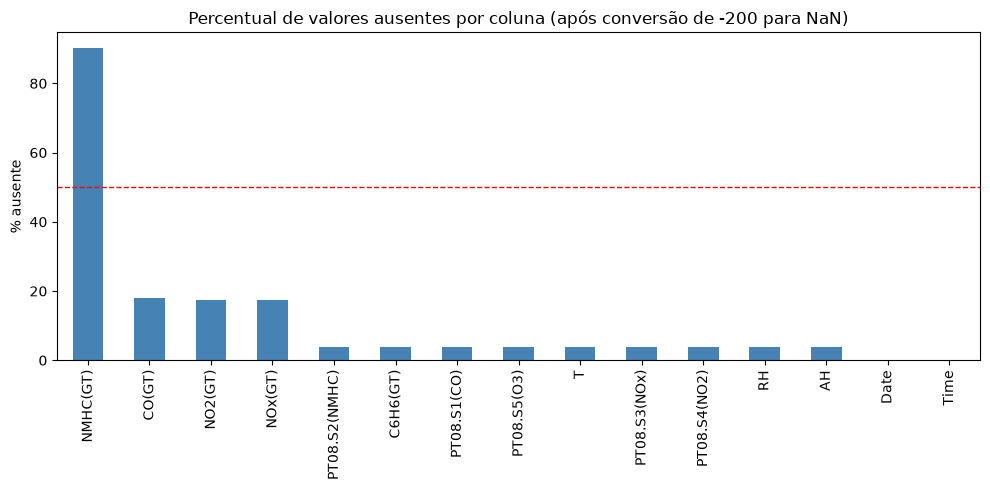

NMHC(GT)         90.231912
CO(GT)           17.986534
NO2(GT)          17.548360
NOx(GT)          17.516298
PT08.S2(NMHC)     3.911510
C6H6(GT)          3.911510
PT08.S1(CO)       3.911510
PT08.S5(O3)       3.911510
T                 3.911510
PT08.S3(NOx)      3.911510
PT08.S4(NO2)      3.911510
RH                3.911510
AH                3.911510
Date              0.000000
Time              0.000000
dtype: float64

In [5]:
# O valor -200 marca leitura de sensor com falha (não é uma medição válida) — convertemos para NaN.

neg200_count = (df.drop(columns=['Date', 'Time']) == -200).sum().sort_values(ascending=False)
print("Contagem de valores -200 por coluna:")
print(neg200_count)

df.replace(-200, np.nan, inplace=True)

missing_pct = df.isna().mean().sort_values(ascending=False) * 100
plt.figure(figsize=(10, 5))
missing_pct.plot(kind='bar', color='steelblue')
plt.title('Percentual de valores ausentes por coluna (após conversão de -200 para NaN)')
plt.ylabel('% ausente')
plt.axhline(50, color='red', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

missing_pct

In [6]:
# NMHC(GT) tem ~90% de valores ausentes, alto demais para imputar sem viés — descartamos a coluna.

df = df.drop(columns=['NMHC(GT)'])
df = df.dropna().reset_index(drop=True)
print("Shape após remover NMHC(GT) e linhas com valores ausentes:", df.shape)
df.describe()

Shape após remover NMHC(GT) e linhas com valores ausentes: (6941, 14)


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,6941.000000,6941.000000,6941.000000,6941.000000,6941.000000,6941.000000,6941.000000,6941.000000,6941.000000,6941.000000,6941.000000,6941.000000
mean,2.182467,1119.913269,10.554488,958.543005,250.671949,816.893387,113.874082,1452.648898,1057.756519,17.755323,48.881905,0.985573
std,1.441158,218.733754,7.465226,264.055002,208.611371,251.897200,47.475017,353.301576,406.509957,8.844909,17.433193,0.401097
min,0.100000,647.000000,0.200000,390.000000,2.000000,322.000000,2.000000,551.000000,221.000000,-1.900000,9.200000,0.184700
25%,1.100000,956.000000,4.900000,760.000000,103.000000,642.000000,79.000000,1207.000000,760.000000,11.200000,35.300000,0.694100
50%,1.900000,1085.000000,8.800000,931.000000,186.000000,786.000000,110.000000,1457.000000,1006.000000,16.800000,49.200000,0.953900
75%,2.900000,1254.000000,14.600000,1135.000000,335.000000,947.000000,142.000000,1683.000000,1322.000000,23.700000,62.200000,1.251600
max,11.900000,2040.000000,63.700000,2214.000000,1479.000000,2683.000000,333.000000,2775.000000,2523.000000,44.600000,88.700000,2.180600


### Conversão de tipos e tendência temporal

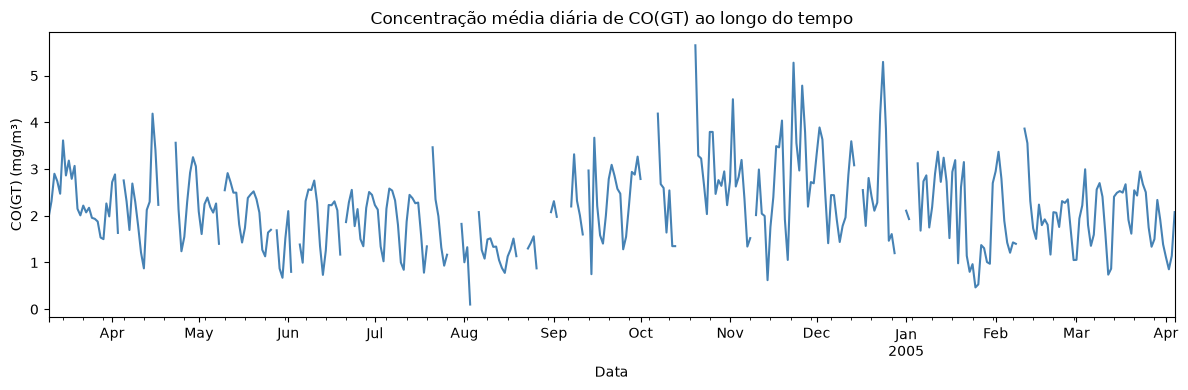

In [7]:
# Sazonalidade esperada (mais CO no inverno). CO(GT) será previsto a partir dos sensores, não da série temporal, então DateTime fica de fora das features.

df['DateTime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H.%M.%S')
df = df.drop(columns=['Date', 'Time'])

plt.figure(figsize=(12, 4))
df.set_index('DateTime')['CO(GT)'].resample('D').mean().plot(color='steelblue')
plt.title('Concentração média diária de CO(GT) ao longo do tempo')
plt.ylabel('CO(GT) (mg/m³)')
plt.xlabel('Data')
plt.tight_layout()
plt.show()

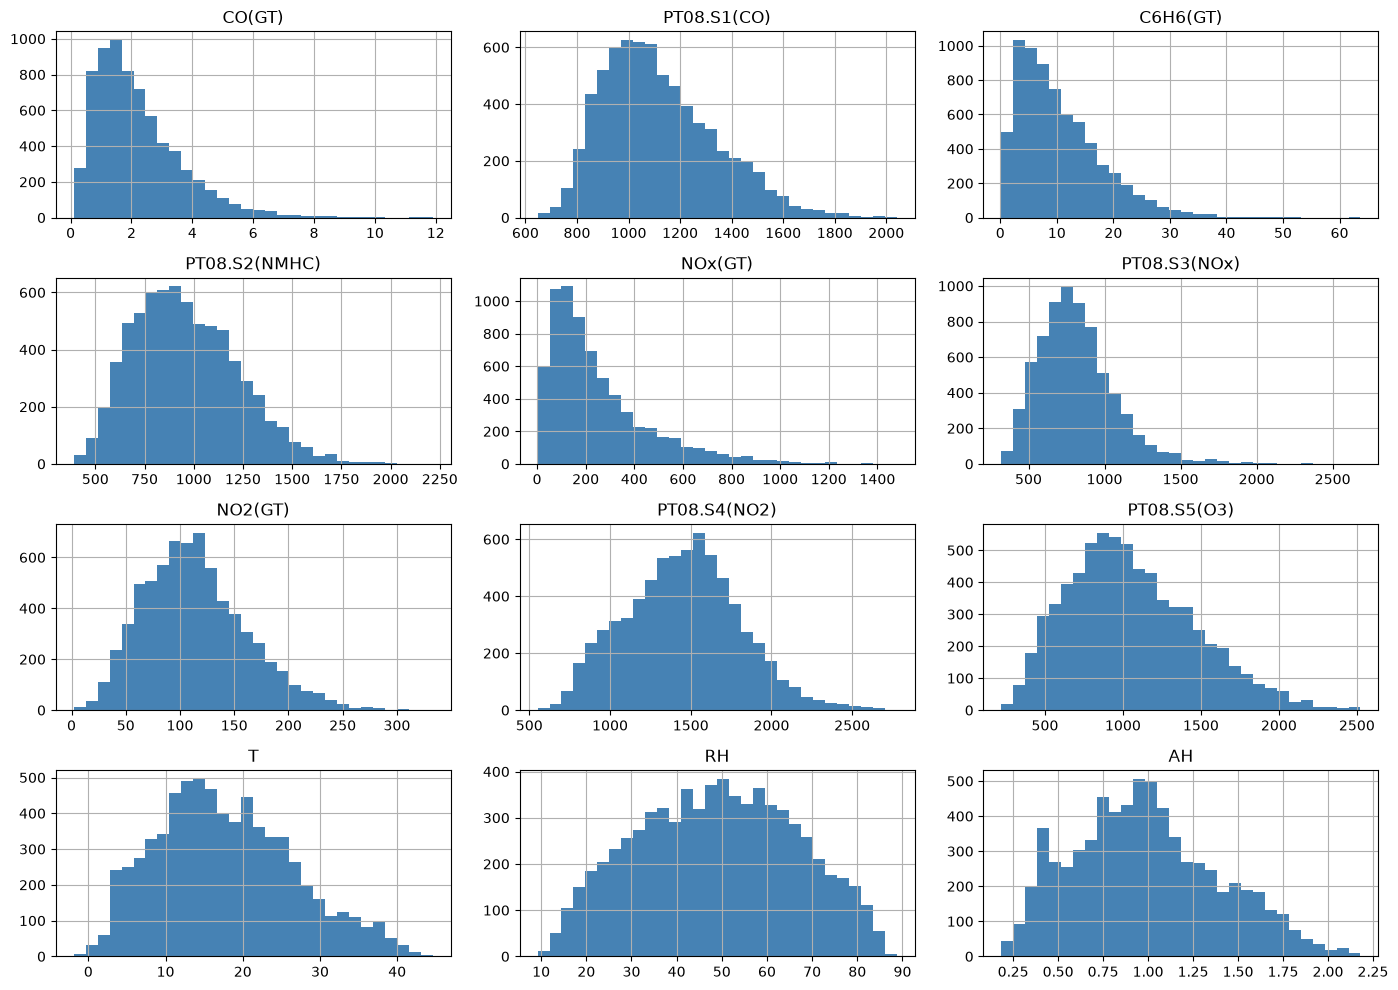

In [8]:
df_model = df.drop(columns=['DateTime'])

df_model.hist(figsize=(14, 10), bins=30, color='steelblue')
plt.tight_layout()
plt.show()

### Correlação entre variáveis

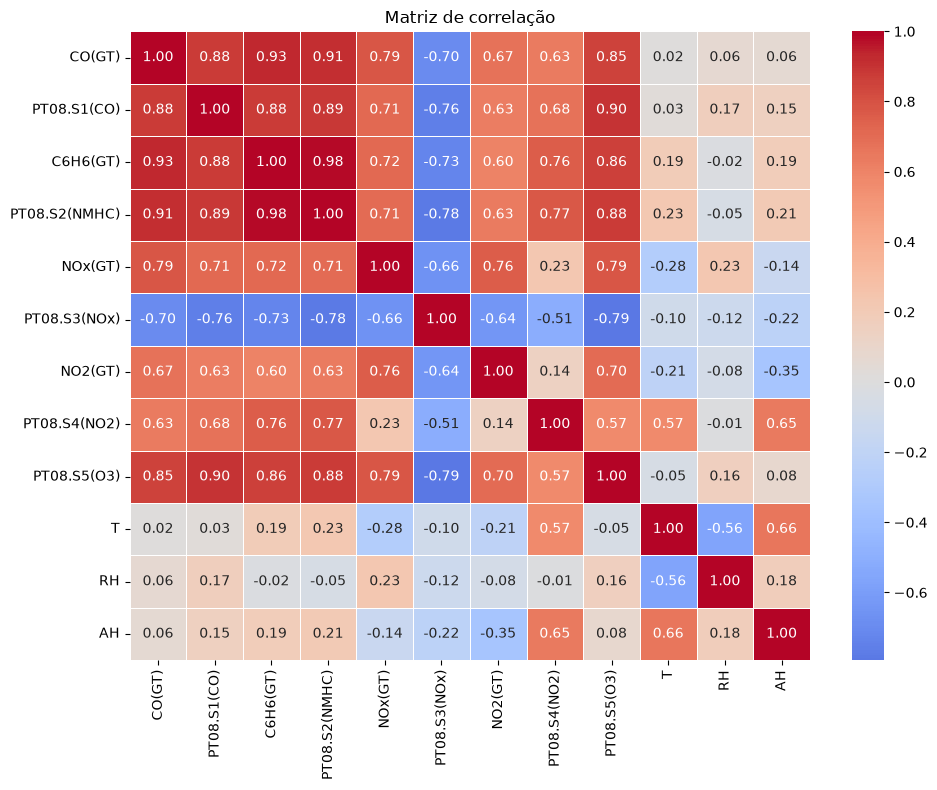

In [9]:
plt.figure(figsize=(10, 8))
corr = df_model.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Matriz de correlação')
plt.tight_layout()
plt.show()

In [10]:
corr['CO(GT)'].sort_values(ascending=False)

CO(GT)           1.000000
C6H6(GT)         0.930008
PT08.S2(NMHC)    0.914310
PT08.S1(CO)      0.877014
PT08.S5(O3)      0.853480
NOx(GT)          0.786456
NO2(GT)          0.673840
PT08.S4(NO2)     0.630834
RH               0.064753
AH               0.059346
T                0.018334
PT08.S3(NOx)    -0.701038
Name: CO(GT), dtype: float64

## Preparação para modelagem

In [11]:
X = df_model.drop(columns=['CO(GT)'])
y = df_model['CO(GT)']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Treino:", X_train.shape, " Teste:", X_test.shape)

Treino: (5552, 11)  Teste: (1389, 11)


In [12]:
def evaluate(name, y_true, y_pred, elapsed=None):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    tempo = f" | tempo: {elapsed:.1f}s" if elapsed is not None else ""
    print(f"[{name}] MAE={mae:.4f}  MSE={mse:.4f}  RMSE={rmse:.4f}  R²={r2:.4f}{tempo}")
    return {'modelo': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

resultados = []

## Modelo 1: MLPRegressor (rede neural)

Começamos pela configuração padrão do scikit-learn.


In [13]:
# Padronizamos as features para o MLP: o gradiente descendente converge mal quando as escalas variam muito
# (ex.: PT08.S1(CO) na casa das centenas/milhares vs. AH em décimos). Árvores (GB) não precisam disso.

mlp_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MLPRegressor(random_state=RANDOM_STATE, max_iter=500, early_stopping=True))
])

t0 = time.time()
mlp_pipe.fit(X_train, y_train)
y_pred = mlp_pipe.predict(X_test)
resultados.append(evaluate('MLP (baseline)', y_test, y_pred, time.time() - t0))

[MLP (baseline)] MAE=0.2329  MSE=0.1355  RMSE=0.3681  R²=0.9282 | tempo: 1.4s


### Ajustando os hiperparâmetros


### GridSearchCV

In [14]:
# hidden_layer_sizes, activation e alpha são os hiperparâmetros de maior impacto no MLPRegressor
# (doc do scikit-learn); alpha em escala log, como a própria doc recomenda para regularização L2.

param_grid_mlp = {
    'model__hidden_layer_sizes': [(50,), (100,), (50, 50)],
    'model__activation': ['relu', 'tanh'],
    'model__alpha': [0.0001, 0.001, 0.01],
}

t0 = time.time()
grid_mlp = GridSearchCV(mlp_pipe, param_grid_mlp, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_mlp.fit(X_train, y_train)
elapsed = time.time() - t0

print("Melhores hiperparâmetros (GridSearchCV):", grid_mlp.best_params_)
y_pred = grid_mlp.predict(X_test)
resultados.append(evaluate('MLP (GridSearchCV)', y_test, y_pred, elapsed))

Melhores hiperparâmetros (GridSearchCV): {'model__activation': 'relu', 'model__alpha': 0.001, 'model__hidden_layer_sizes': (50, 50)}
[MLP (GridSearchCV)] MAE=0.2343  MSE=0.1302  RMSE=0.3609  R²=0.9310 | tempo: 35.3s


### RandomizedSearchCV

In [15]:
# Mesmo espaço do grid, mais amplo, e learning_rate_init (também em log) sorteado em vez de fixo.

param_dist_mlp = {
    'model__hidden_layer_sizes': [(50,), (100,), (150,), (50, 50), (100, 50), (100, 100)],
    'model__activation': ['relu', 'tanh', 'logistic'],
    'model__alpha': loguniform(1e-5, 1e-1),
    'model__learning_rate_init': loguniform(1e-4, 1e-1),
}

t0 = time.time()
random_mlp = RandomizedSearchCV(
    mlp_pipe, param_dist_mlp, n_iter=20, cv=5,
    scoring='neg_root_mean_squared_error', n_jobs=-1, random_state=RANDOM_STATE
)
random_mlp.fit(X_train, y_train)
elapsed = time.time() - t0

print("Melhores hiperparâmetros (RandomizedSearchCV):", random_mlp.best_params_)
y_pred = random_mlp.predict(X_test)
resultados.append(evaluate('MLP (RandomizedSearchCV)', y_test, y_pred, elapsed))

Melhores hiperparâmetros (RandomizedSearchCV): {'model__activation': 'relu', 'model__alpha': np.float64(0.06993395623207713), 'model__hidden_layer_sizes': (100, 50), 'model__learning_rate_init': np.float64(0.001465655388622534)}
[MLP (RandomizedSearchCV)] MAE=0.2341  MSE=0.1386  RMSE=0.3723  R²=0.9266 | tempo: 63.9s


### Otimização Bayesiana (Optuna)

In [16]:
# TPE: usa o histórico de tentativas para escolher a próxima combinação, em vez de sortear (Random) ou
# varrer tudo (Grid). Mesmo espaço de busca do Random Search, para comparação justa.

def objective_mlp(trial):
    hidden_opcoes = ['50', '100', '150', '50,50', '100,50', '100,100']
    hidden_str = trial.suggest_categorical('hidden_layer_sizes', hidden_opcoes)
    hidden = tuple(int(x) for x in hidden_str.split(','))
    activation = trial.suggest_categorical('activation', ['relu', 'tanh', 'logistic'])
    alpha = trial.suggest_float('alpha', 1e-5, 1e-1, log=True)
    learning_rate_init = trial.suggest_float('learning_rate_init', 1e-4, 1e-1, log=True)

    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', MLPRegressor(
            hidden_layer_sizes=hidden, activation=activation, alpha=alpha,
            learning_rate_init=learning_rate_init,
            random_state=RANDOM_STATE, max_iter=500, early_stopping=True
        ))
    ])
    score = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
    return score.mean()

t0 = time.time()
study_mlp = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_mlp.optimize(objective_mlp, n_trials=20, show_progress_bar=False)
elapsed = time.time() - t0

best_mlp_params = study_mlp.best_params
hidden = tuple(int(x) for x in best_mlp_params['hidden_layer_sizes'].split(','))
best_mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MLPRegressor(
        hidden_layer_sizes=hidden, activation=best_mlp_params['activation'],
        alpha=best_mlp_params['alpha'], learning_rate_init=best_mlp_params['learning_rate_init'],
        random_state=RANDOM_STATE, max_iter=500, early_stopping=True
    ))
])
best_mlp.fit(X_train, y_train)
y_pred = best_mlp.predict(X_test)

print("Melhores hiperparâmetros (Optuna):", best_mlp_params)
resultados.append(evaluate('MLP (Bayesiana/Optuna)', y_test, y_pred, elapsed))

Melhores hiperparâmetros (Optuna): {'hidden_layer_sizes': '100,50', 'activation': 'relu', 'alpha': 0.0009368813117080879, 'learning_rate_init': 0.003685673645315139}
[MLP (Bayesiana/Optuna)] MAE=0.2279  MSE=0.1303  RMSE=0.3610  R²=0.9310 | tempo: 57.4s


## Modelo 2: GradientBoostingRegressor (ensemble de boosting)

Mesma sequência: baseline e depois otimização.


In [17]:
gb_baseline = GradientBoostingRegressor(random_state=RANDOM_STATE)

t0 = time.time()
gb_baseline.fit(X_train, y_train)
y_pred = gb_baseline.predict(X_test)
resultados.append(evaluate('GB (baseline)', y_test, y_pred, time.time() - t0))

[GB (baseline)] MAE=0.2540  MSE=0.1498  RMSE=0.3870  R²=0.9207 | tempo: 1.0s


### Ajustando os hiperparâmetros


### GridSearchCV

In [18]:
# n_estimators, learning_rate e max_depth: a doc do GradientBoostingRegressor destaca o trade-off direto
# entre learning_rate e n_estimators, e recomenda ajustar max_depth à complexidade dos dados.

param_grid_gb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [2, 3, 4],
}

t0 = time.time()
grid_gb = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE), param_grid_gb,
    cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
)
grid_gb.fit(X_train, y_train)
elapsed = time.time() - t0

print("Melhores hiperparâmetros (GridSearchCV):", grid_gb.best_params_)
y_pred = grid_gb.predict(X_test)
resultados.append(evaluate('GB (GridSearchCV)', y_test, y_pred, elapsed))

Melhores hiperparâmetros (GridSearchCV): {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 300}
[GB (GridSearchCV)] MAE=0.2396  MSE=0.1350  RMSE=0.3674  R²=0.9285 | tempo: 48.3s


### RandomizedSearchCV

In [19]:
# Espaço maior: subsample e min_samples_leaf entram aqui — a doc indica ambos como formas de reduzir
# variância (stochastic gradient boosting) e suavizar o modelo.

param_dist_gb = {
    'n_estimators': randint(50, 500),
    'learning_rate': loguniform(0.005, 0.3),
    'max_depth': randint(2, 6),
    'subsample': uniform(0.6, 0.4),
    'min_samples_leaf': randint(1, 20),
}

t0 = time.time()
random_gb = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE), param_dist_gb,
    n_iter=20, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1, random_state=RANDOM_STATE
)
random_gb.fit(X_train, y_train)
elapsed = time.time() - t0

print("Melhores hiperparâmetros (RandomizedSearchCV):", random_gb.best_params_)
y_pred = random_gb.predict(X_test)
resultados.append(evaluate('GB (RandomizedSearchCV)', y_test, y_pred, elapsed))

Melhores hiperparâmetros (RandomizedSearchCV): {'learning_rate': np.float64(0.0820192671822916), 'max_depth': 5, 'min_samples_leaf': 8, 'n_estimators': 480, 'subsample': np.float64(0.6693458614031088)}
[GB (RandomizedSearchCV)] MAE=0.2325  MSE=0.1230  RMSE=0.3507  R²=0.9349 | tempo: 49.1s


### Otimização Bayesiana (Optuna)

In [20]:
# Mesmo espaço do Random Search, com busca guiada pelo TPE.

def objective_gb(trial):
    n_estimators = trial.suggest_int('n_estimators', 50, 500)
    learning_rate = trial.suggest_float('learning_rate', 0.005, 0.3, log=True)
    max_depth = trial.suggest_int('max_depth', 2, 6)
    subsample = trial.suggest_float('subsample', 0.6, 1.0)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 20)

    model = GradientBoostingRegressor(
        n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth,
        subsample=subsample, min_samples_leaf=min_samples_leaf, random_state=RANDOM_STATE
    )
    score = cross_val_score(model, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
    return score.mean()

t0 = time.time()
study_gb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_gb.optimize(objective_gb, n_trials=20, show_progress_bar=False)
elapsed = time.time() - t0

best_gb_params = study_gb.best_params
best_gb = GradientBoostingRegressor(**best_gb_params, random_state=RANDOM_STATE)
best_gb.fit(X_train, y_train)
y_pred = best_gb.predict(X_test)

print("Melhores hiperparâmetros (Optuna):", best_gb_params)
resultados.append(evaluate('GB (Bayesiana/Optuna)', y_test, y_pred, elapsed))

Melhores hiperparâmetros (Optuna): {'n_estimators': 253, 'learning_rate': 0.09150275996438541, 'max_depth': 5, 'subsample': 0.7718470808683202, 'min_samples_leaf': 2}
[GB (Bayesiana/Optuna)] MAE=0.2320  MSE=0.1246  RMSE=0.3529  R²=0.9340 | tempo: 73.2s


## Comparação consolidada dos resultados

In [21]:
df_resultados = pd.DataFrame(resultados).set_index('modelo')
df_resultados = df_resultados[['MAE', 'MSE', 'RMSE', 'R2']]
df_resultados.round(4)

,MAE,MSE,RMSE,R2
modelo,,,,
MLP (baseline),0.2329,0.1355,0.3681,0.9282
MLP (GridSearchCV),0.2343,0.1302,0.3609,0.9310
MLP (RandomizedSearchCV),0.2341,0.1386,0.3723,0.9266
MLP (Bayesiana/Optuna),0.2279,0.1303,0.3610,0.9310
GB (baseline),0.2540,0.1498,0.3870,0.9207
GB (GridSearchCV),0.2396,0.1350,0.3674,0.9285
GB (RandomizedSearchCV),0.2325,0.1230,0.3507,0.9349
GB (Bayesiana/Optuna),0.2320,0.1246,0.3529,0.9340


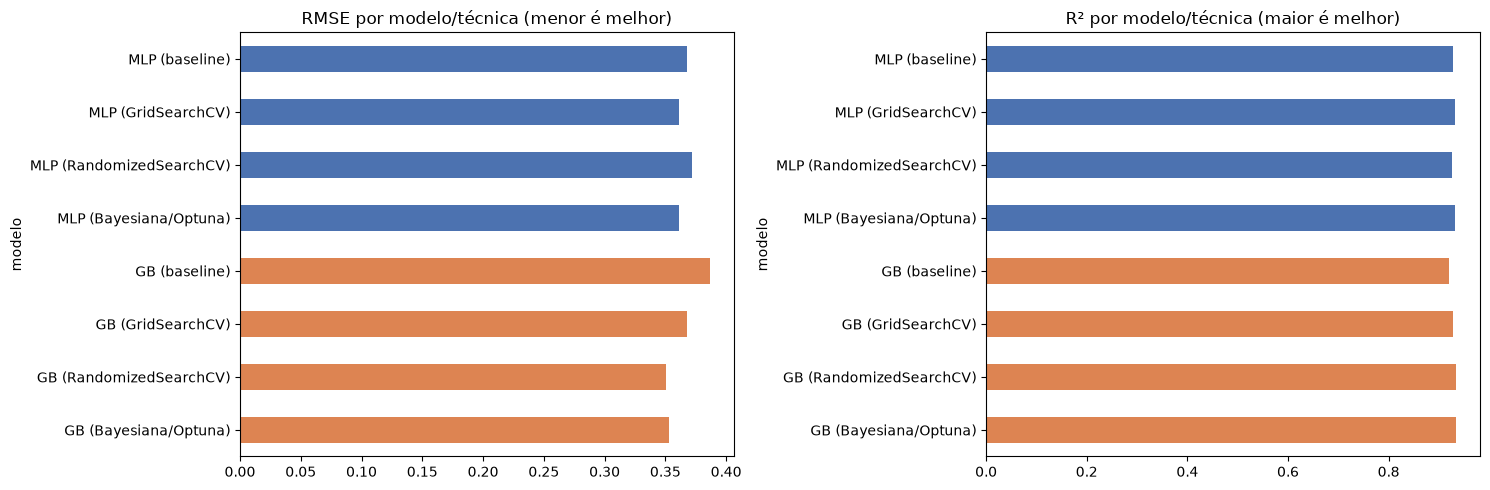

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cores = ['#4C72B0' if 'MLP' in m else '#DD8452' for m in df_resultados.index]

df_resultados['RMSE'].plot(kind='barh', ax=axes[0], color=cores)
axes[0].set_title('RMSE por modelo/técnica (menor é melhor)')
axes[0].invert_yaxis()

df_resultados['R2'].plot(kind='barh', ax=axes[1], color=cores)
axes[1].set_title('R² por modelo/técnica (maior é melhor)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

In [23]:
melhor_modelo = df_resultados['RMSE'].idxmin()
print(f"Melhor configuração geral (menor RMSE): {melhor_modelo}")
df_resultados.loc[[melhor_modelo]]

Melhor configuração geral (menor RMSE): GB (RandomizedSearchCV)


,MAE,MSE,RMSE,R2
modelo,,,,
GB (RandomizedSearchCV),0.232472,0.122996,0.350708,0.934857


### Real vs. previsto — melhor modelo

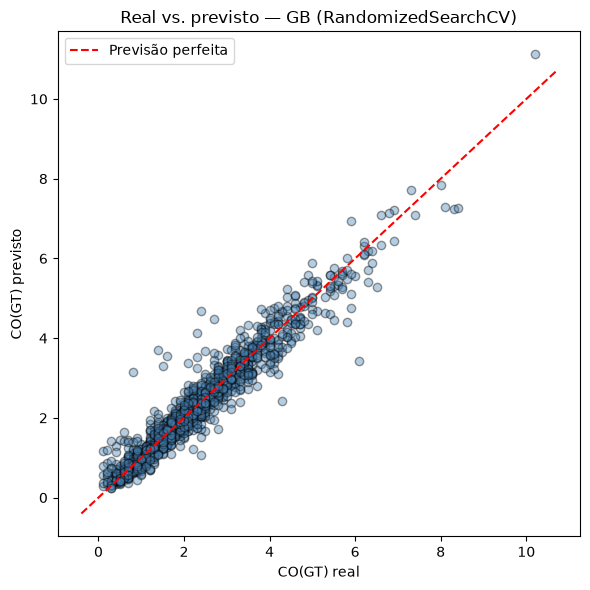

In [24]:
modelos_treinados = {
    'MLP (baseline)': mlp_pipe,
    'MLP (GridSearchCV)': grid_mlp.best_estimator_,
    'MLP (RandomizedSearchCV)': random_mlp.best_estimator_,
    'MLP (Bayesiana/Optuna)': best_mlp,
    'GB (baseline)': gb_baseline,
    'GB (GridSearchCV)': grid_gb.best_estimator_,
    'GB (RandomizedSearchCV)': random_gb.best_estimator_,
    'GB (Bayesiana/Optuna)': best_gb,
}

melhor_estimator = modelos_treinados[melhor_modelo]
y_pred_melhor = melhor_estimator.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_melhor, alpha=0.4, edgecolor='k', color='steelblue')
lims = [y_test.min() - 0.5, y_test.max() + 0.5]
plt.plot(lims, lims, 'r--', label='Previsão perfeita')
plt.xlabel('CO(GT) real')
plt.ylabel('CO(GT) previsto')
plt.title(f'Real vs. previsto — {melhor_modelo}')
plt.legend()
plt.tight_layout()
plt.show()

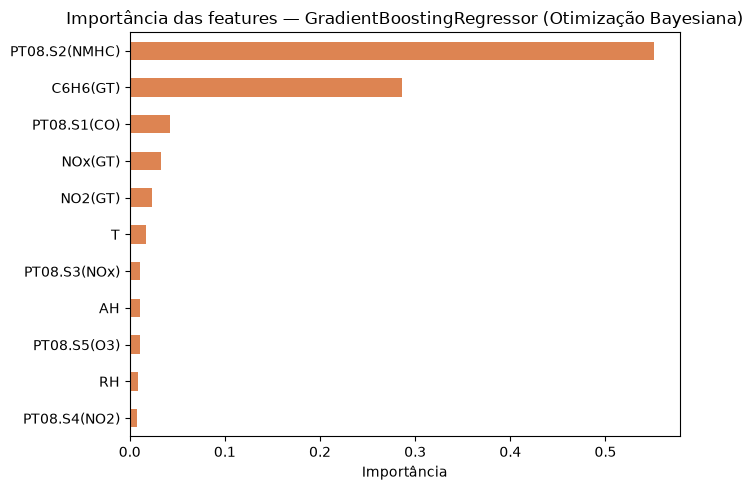

PT08.S2(NMHC)    0.550831
C6H6(GT)         0.286465
PT08.S1(CO)      0.042121
NOx(GT)          0.032614
NO2(GT)          0.023288
T                0.017018
PT08.S3(NOx)     0.010882
AH               0.010426
PT08.S5(O3)      0.010421
RH               0.008331
PT08.S4(NO2)     0.007604
dtype: float64

In [25]:
importancias = pd.Series(best_gb.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(7, 5))
importancias.plot(kind='barh', color='#DD8452')
plt.title('Importância das features — GradientBoostingRegressor (Otimização Bayesiana)')
plt.xlabel('Importância')
plt.tight_layout()
plt.show()

importancias.sort_values(ascending=False)

## Conclusão

No MLP, a otimização ajudou pouco: o RMSE foi de 0,368 (baseline) para 0,361 no Grid e no Optuna — uma melhora pequena. Chama atenção que o Random Search piorou o resultado (RMSE 0,372), pior que o próprio baseline: com um espaço contínuo e só 20 sorteios, ele pode simplesmente não visitar nenhuma região boa. Já o Optuna nunca ficou abaixo do baseline em nenhum dos dois modelos, e foi quem obteve o menor MAE do notebook (0,2279, no MLP) — coerente com o fato de aprender com as tentativas anteriores em vez de sortear ou varrer uma grade às cegas.

No GradientBoostingRegressor a otimização valeu bem mais a pena: RMSE caiu de 0,387 para 0,351 com o Random Search, quase empatado com o Optuna (0,353). Os hiperparâmetros default do GB parecem estar mais longe do ideal para este dataset do que os do MLP.

Comparando os dois algoritmos em suas melhores versões, o GB (Random Search: MAE 0,2325, RMSE 0,3507, R² 0,935) supera o MLP (Optuna: MAE 0,2279, RMSE 0,3610, R² 0,931) em RMSE e R², embora o MLP tenha o menor MAE isolado. Como o RMSE pesa mais os erros grandes, o GB parece errar feio com menos frequência. Faz sentido: as features aqui são leituras de sensores tabulares, um cenário em que ensembles de árvores costumam se sair bem sem exigir escalonamento ou muita experimentação de arquitetura — ao contrário de uma rede neural, que em geral precisa de mais dados e mais ajuste fino para superar árvores em problemas tabulares deste porte. O gráfico de importância de features confirma o que já aparecia na correlação: `C6H6(GT)`, `PT08.S2(NMHC)` e `PT08.S1(CO)` — co-poluentes de combustão — são quem mais pesa na previsão.

**Melhor modelo: `GradientBoostingRegressor` otimizado com `RandomizedSearchCV`** (MAE = 0,2325, RMSE = 0,3507, R² = 0,935). Entre as técnicas de otimização, a Bayesiana foi a mais consistente das três — nunca piorou o baseline —, enquanto o Random Search foi o mais irregular, com o melhor resultado absoluto do notebook (no GB) e o pior (no MLP).
